# TP5 - Punto 3
## Decaimiento radioactivo

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def resolver_edo_escalar(f, y0, t_final, n=500, rtol=1e-9, atol=1e-12):
    """Resuelve una EDO escalar y devuelve t, y."""
    t_eval = np.linspace(0, t_final, n)
    sol = solve_ivp(
        fun=lambda t, y: [f(t, y[0])],
        t_span=(0, t_final),
        y0=[y0],
        t_eval=t_eval,
        rtol=rtol,
        atol=atol,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.t, sol.y[0]

def valores_en(t, y, puntos, nombre="valor"):
    return pd.DataFrame({
        "t": puntos,
        nombre: np.interp(puntos, t, y),
    })

def primer_tiempo_cerca(t, y, objetivo, tolerancia):
    cerca = np.where(np.abs(y - objetivo) <= tolerancia)[0]
    if len(cerca) == 0:
        return np.nan
    return t[cerca[0]]

def mostrar_tabla(df, decimales=4):
    display(df.round(decimales).style.hide(axis="index"))

## 3. Decaimiento radioactivo

Modelo:

`dN/dt = -lambda N`

En esta seccion el tiempo `t` se mide en anos y `lambda` tiene unidades de `1/ano`.

`N0` es la cantidad inicial de sustancia y `lambda` es la constante de desintegracion. Si `lambda > 0`, la cantidad disminuye hacia `0`. La vida media es:

`t_1/2 = ln(2) / lambda`

Ejemplo real: el carbono 14 tiene una vida media de aproximadamente `5730 anos`. Entonces:

`lambda = ln(2) / 5730`

Este modelo es la misma ecuacion que Malthus con tasa negativa. Si en Malthus `dP/dt = rP`, aca se puede pensar como `r = -lambda`. Por eso `lambda < 0` se convierte en crecimiento exponencial, sin sentido fisico para radioactividad.

Caso base: N0=800, lambda=0.12 1/ano
Vida media: 5.7762 anos
Carbono 14: lambda = 0.00012097 1/ano
Error maximo contra la formula cerrada: 1.89e-07


t,N(t)
0.000000,800.000000
5.000000,439.054100
10.000000,240.957500
20.000000,72.575200
5.776200,400.001000


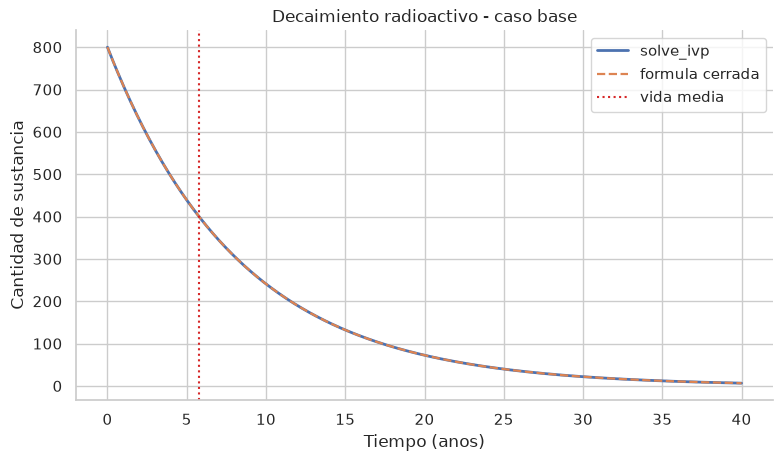

In [2]:
def decaimiento_rhs(lambda_param):
    return lambda t, N: -lambda_param * N

def resolver_decaimiento(N0=800, lambda_param=0.12, t_final=40):
    return resolver_edo_escalar(decaimiento_rhs(lambda_param), N0, t_final)

def decaimiento_teorica(t, N0, lambda_param):
    return N0 * np.exp(-lambda_param * t)

N0 = 800
lambda_param = 0.12
t, N = resolver_decaimiento(N0=N0, lambda_param=lambda_param, t_final=40)
N_exacta = decaimiento_teorica(t, N0, lambda_param)
vida_media = np.log(2) / lambda_param
lambda_c14 = np.log(2) / 5730

print(f"Caso base: N0={N0}, lambda={lambda_param} 1/ano")
print(f"Vida media: {vida_media:.4f} anos")
print(f"Carbono 14: lambda = {lambda_c14:.8f} 1/ano")
print(f"Error maximo contra la formula cerrada: {np.max(np.abs(N - N_exacta)):.2e}")
mostrar_tabla(valores_en(t, N, [0, 5, 10, 20, vida_media], "N(t)"))

plt.plot(t, N, label="solve_ivp", linewidth=2)
plt.plot(t, N_exacta, "--", label="formula cerrada", linewidth=1.6)
plt.axvline(vida_media, color="tab:red", linestyle=":", label="vida media")
plt.title("Decaimiento radioactivo - caso base")
plt.xlabel("Tiempo (anos)")
plt.ylabel("Cantidad de sustancia")
plt.legend()
plt.show()

### Variar `lambda` con `N0` fijo

Cuanto mayor es `lambda`, mas rapido cae la cantidad de sustancia y menor es la vida media.

Se separa `lambda < 0` en otro grafico porque ese caso se transforma en crecimiento exponencial y puede aplastar visualmente las curvas de decaimiento.

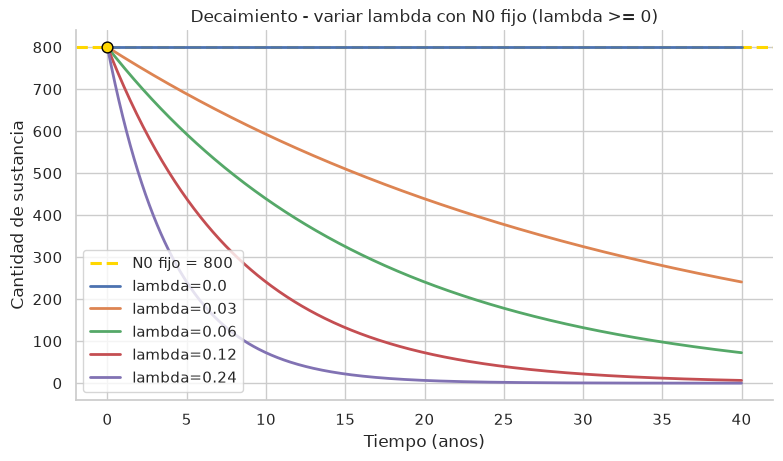

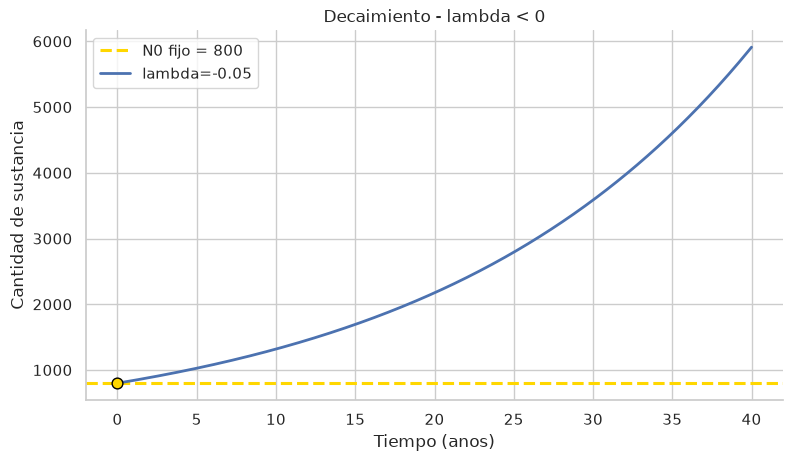

lambda (1/ano),N0 fijo,N despues de 40 anos,vida media (anos),comportamiento,interpretacion
0.000000,800,800.000000,no aplica,constante,no hay decaimiento porque lambda = 0
0.030000,800,240.955400,23.10,decae,"a mayor lambda, menor vida media y mas rapido decae"
0.060000,800,72.574400,11.55,decae,"a mayor lambda, menor vida media y mas rapido decae"
0.120000,800,6.583800,5.78,decae,"a mayor lambda, menor vida media y mas rapido decae"
0.240000,800,0.054200,2.89,decae,"a mayor lambda, menor vida media y mas rapido decae"
-0.050000,800,5911.244900,no aplica,crece,lambda negativa invierte el signo: crecimiento exponencial sin sentido fisico para radioactividad


In [7]:
N0 = 800
lambda_valores_no_negativos = [0.00, 0.03, 0.06, 0.12, 0.24]
lambda_valores_negativos = [-0.05]
resumen = []

plt.figure(figsize=(9, 4.8))
plt.axhline(N0, color="gold", linestyle="--", linewidth=2.2, label=f"N0 fijo = {N0}")
plt.scatter([0], [N0], color="gold", edgecolor="black", s=60, zorder=5)
for li in lambda_valores_no_negativos:
    t, N = resolver_decaimiento(N0=N0, lambda_param=li, t_final=40)
    plt.plot(t, N, linewidth=2, label=f"lambda={li}")
    resumen.append({
        "lambda (1/ano)": li,
        "N0 fijo": N0,
        "N despues de 40 anos": N[-1],
        "vida media (anos)": "no aplica" if li == 0 else np.log(2) / li,
        "comportamiento": "constante" if li == 0 else "decae",
        "interpretacion": "no hay decaimiento porque lambda = 0" if li == 0 else "a mayor lambda, menor vida media y mas rapido decae",
    })
plt.title("Decaimiento - variar lambda con N0 fijo (lambda >= 0)")
plt.xlabel("Tiempo (anos)")
plt.ylabel("Cantidad de sustancia")
plt.legend()
plt.show()

plt.figure(figsize=(9, 4.8))
plt.axhline(N0, color="gold", linestyle="--", linewidth=2.2, label=f"N0 fijo = {N0}")
plt.scatter([0], [N0], color="gold", edgecolor="black", s=60, zorder=5)
for li in lambda_valores_negativos:
    t, N = resolver_decaimiento(N0=N0, lambda_param=li, t_final=40)
    plt.plot(t, N, linewidth=2, label=f"lambda={li}")
    resumen.append({
        "lambda (1/ano)": li,
        "N0 fijo": N0,
        "N despues de 40 anos": N[-1],
        "vida media (anos)": "no aplica",
        "comportamiento": "crece",
        "interpretacion": "lambda negativa invierte el signo: crecimiento exponencial sin sentido fisico para radioactividad",
    })
plt.title("Decaimiento - lambda < 0")
plt.xlabel("Tiempo (anos)")
plt.ylabel("Cantidad de sustancia")
plt.legend()
plt.show()

tabla_lambda = pd.DataFrame(resumen)
columnas_numericas = ["lambda (1/ano)", "N despues de 40 anos"]
tabla_lambda[columnas_numericas] = tabla_lambda[columnas_numericas].round(4)
tabla_lambda["vida media (anos)"] = tabla_lambda["vida media (anos)"].apply(
    lambda x: f"{x:.2f}" if isinstance(x, (int, float, np.floating)) else x
)

display(
    tabla_lambda.style.hide(axis="index").set_properties(
        subset=["interpretacion"],
        **{"white-space": "normal", "text-align": "left"}
    )
)

### Variar `N0` con `lambda` fijo

`N0` escala la curva. La vida media no depende de la cantidad inicial: con el mismo `lambda`, todos los casos tardan lo mismo en reducirse a la mitad.

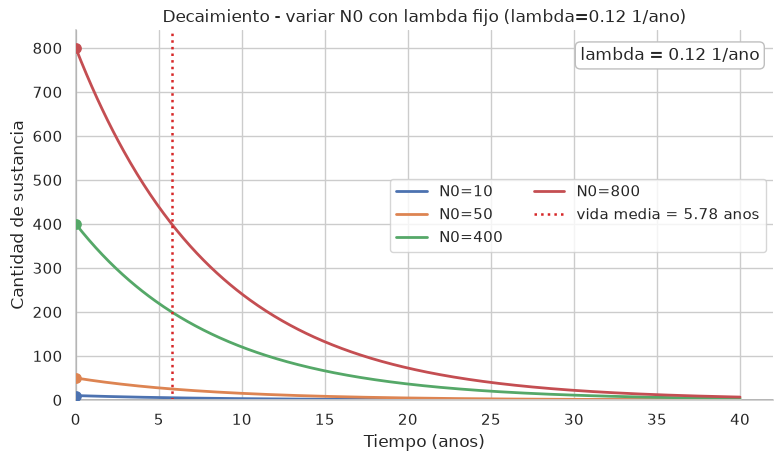

N0,lambda fijo,vida media,N en vida media,N0/2,interpretacion
10,0.120000,5.776200,5.000000,5.000000,la vida media es la misma para cualquier N0
50,0.120000,5.776200,25.000100,25.000000,la vida media es la misma para cualquier N0
400,0.120000,5.776200,200.000500,200.000000,la vida media es la misma para cualquier N0
800,0.120000,5.776200,400.001000,400.000000,la vida media es la misma para cualquier N0


In [8]:
lambda_param = 0.12
N0_valores = [10, 50, 400, 800]
vida_media = np.log(2) / lambda_param
resumen = []

plt.figure(figsize=(9, 4.8))
plt.axhline(0, color="black", linewidth=1.2)
plt.axvline(0, color="black", linewidth=1.2)
for N0i in N0_valores:
    t, N = resolver_decaimiento(N0=N0i, lambda_param=lambda_param, t_final=40)
    N_en_vida_media = np.interp(vida_media, t, N)
    plt.plot(t, N, linewidth=2, label=f"N0={N0i}")
    plt.scatter([0], [N0i], s=45, zorder=5)
    resumen.append({
        "N0": N0i,
        "lambda fijo": lambda_param,
        "vida media": vida_media,
        "N en vida media": N_en_vida_media,
        "N0/2": N0i / 2,
        "interpretacion": "la vida media es la misma para cualquier N0",
    })

plt.axvline(vida_media, color="tab:red", linestyle=":", linewidth=1.8, label=f"vida media = {vida_media:.2f} anos")
plt.annotate(
    f"lambda = {lambda_param} 1/ano",
    xy=(0.98, 0.92),
    xycoords="axes fraction",
    ha="right",
    bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "0.75"},
)
plt.title(f"Decaimiento - variar N0 con lambda fijo (lambda={lambda_param} 1/ano)")
plt.xlabel("Tiempo (anos)")
plt.ylabel("Cantidad de sustancia")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend(ncol=2)
plt.show()

mostrar_tabla(pd.DataFrame(resumen))

### Casos especiales

Esta tabla resume casos borde del modelo. Sirve para separar el calculo matematico de la interpretacion fisica.

In [11]:
lambda_base = 0.12
vida_media_base = np.log(2) / lambda_base
vidas_medias_menor_1_pct = np.ceil(np.log(0.01) / np.log(0.5))
tiempo_menor_1_pct = vidas_medias_menor_1_pct * vida_media_base

casos_decaimiento = [
    {"caso": "lambda = 0", "N0": 800, "lambda": 0, "t_final": 40},
    {"caso": "lambda < 0", "N0": 800, "lambda": -0.05, "t_final": 40},
    {"caso": "N0 = 0", "N0": 0, "lambda": 0.12, "t_final": 40},
    {"caso": "N0 < 0", "N0": -800, "lambda": 0.12, "t_final": 40},
    {"caso": "lambda grande", "N0": 800, "lambda": 0.60, "t_final": 40},
    {"caso": "nunca llega a 0", "N0": 800, "lambda": 0.12, "t_final": tiempo_menor_1_pct},
    {"caso": "N0 pequeno", "N0": 10, "lambda": 0.12, "t_final": 5 * vida_media_base},
]

filas = []
for caso in casos_decaimiento:
    t, N = resolver_decaimiento(N0=caso["N0"], lambda_param=caso["lambda"], t_final=caso["t_final"])
    filas.append({
        "caso": caso["caso"],
        "N0": caso["N0"],
        "lambda": caso["lambda"],
        "N al final": N[-1],
        "dato extra": (
            f"menos de 1% despues de {vidas_medias_menor_1_pct:.0f} vidas medias" if caso["caso"] == "nunca llega a 0" else
            "puede dar fracciones de atomos" if caso["caso"] == "N0 pequeno" else
            ""
        ),
        "interpretacion": (
            "cantidad constante" if caso["lambda"] == 0 else
            "crecimiento no fisico" if caso["lambda"] < 0 else
            "solucion nula" if caso["N0"] == 0 else
            "no fisico: cantidad negativa" if caso["N0"] < 0 else
            "decaimiento muy rapido" if caso["caso"] == "lambda grande" else
            "el modelo se acerca a 0 pero nunca llega exactamente" if caso["caso"] == "nunca llega a 0" else
            "el decaimiento real es aleatorio; el modelo es un promedio para muchas particulas"
        ),
    })

mostrar_tabla(pd.DataFrame(filas))

caso,N0,lambda,N al final,dato extra,interpretacion
lambda = 0,800,0.000000,800.000000,,cantidad constante
lambda < 0,800,-0.050000,5911.244900,,crecimiento no fisico
N0 = 0,0,0.120000,0.000000,,solucion nula
N0 < 0,-800,0.120000,-6.583800,,no fisico: cantidad negativa
lambda grande,800,0.600000,0.000000,,decaimiento muy rapido
nunca llega a 0,800,0.120000,6.250000,menos de 1% despues de 7 vidas medias,el modelo se acerca a 0 pero nunca llega exactamente
N0 pequeno,10,0.120000,0.312500,puede dar fracciones de atomos,el decaimiento real es aleatorio; el modelo es un promedio para muchas particulas


### Graficos de casos especiales

Estos graficos muestran los casos borde de la tabla. Se separan en varios paneles para que los casos que crecen mucho o que toman valores negativos no oculten a los demas.

La linea negra marca `N = 0`. El punto amarillo marca la cantidad inicial `N0`. En los casos donde ayuda, se agrega una referencia: `N = 1` para recordar que no tiene sentido hablar de fracciones de atomos, y `1% de N0` para mostrar que el modelo se acerca a cero pero no lo alcanza exactamente.

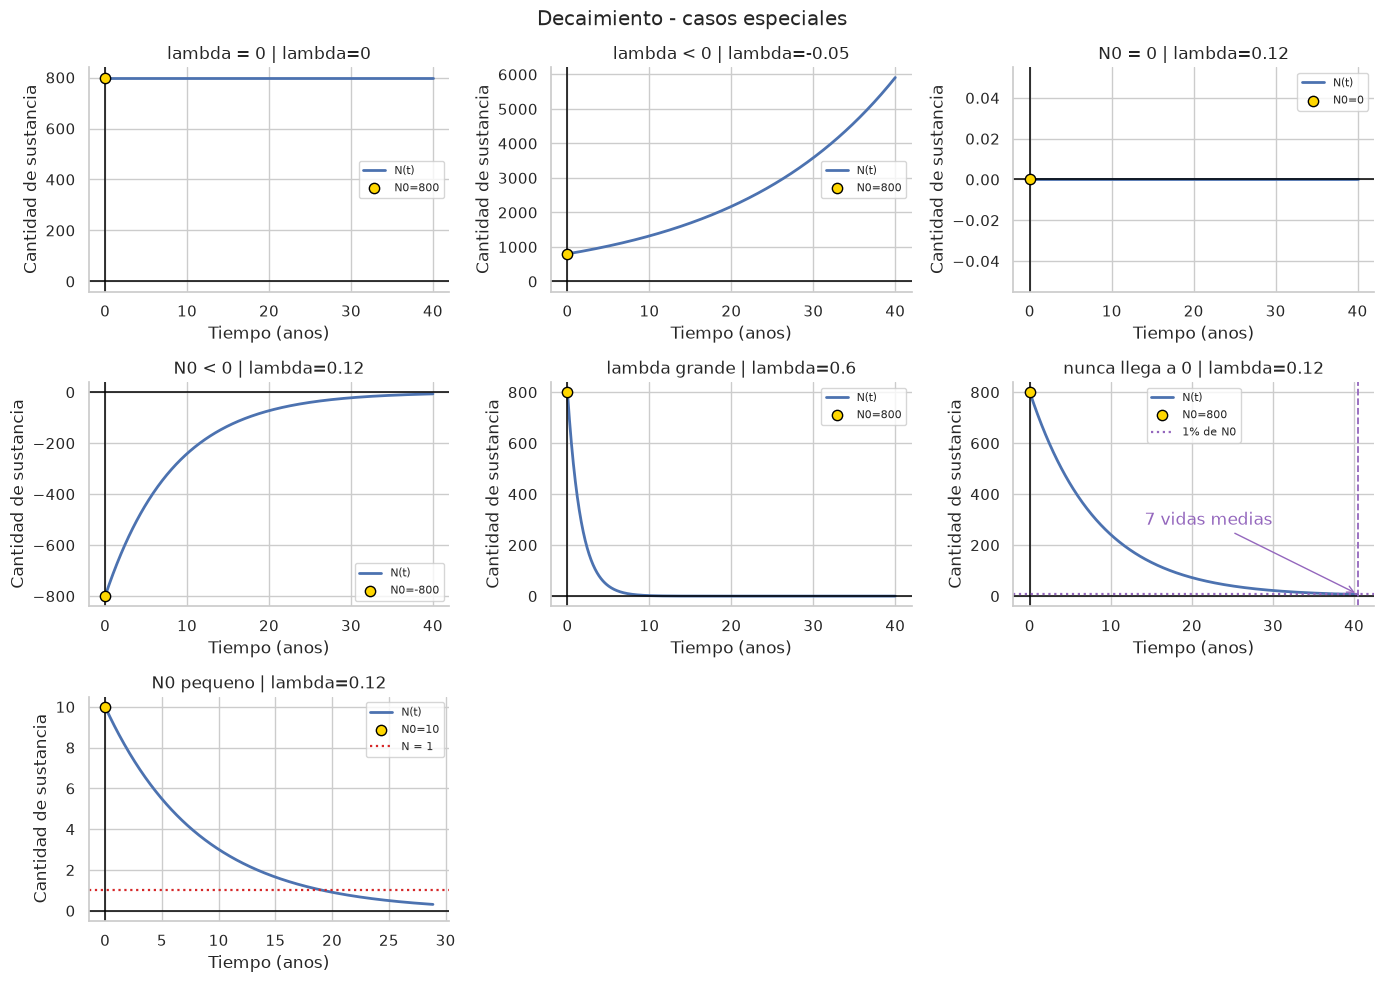

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.ravel()

for ax, caso in zip(axes, casos_decaimiento):
    t, N = resolver_decaimiento(N0=caso["N0"], lambda_param=caso["lambda"], t_final=caso["t_final"])
    ax.plot(t, N, linewidth=2, label="N(t)")
    ax.axhline(0, color="black", linewidth=1.1)
    ax.axvline(0, color="black", linewidth=1.1)
    ax.scatter([0], [caso["N0"]], color="gold", edgecolor="black", s=55, zorder=5, label=f"N0={caso['N0']}")

    if caso["caso"] == "nunca llega a 0":
        ax.axhline(0.01 * caso["N0"], color="tab:purple", linestyle=":", linewidth=1.6, label="1% de N0")
        ax.axvline(tiempo_menor_1_pct, color="tab:purple", linestyle="--", linewidth=1.3)
        ax.annotate(
            f"{vidas_medias_menor_1_pct:.0f} vidas medias",
            xy=(tiempo_menor_1_pct, 0.01 * caso["N0"]),
            xytext=(tiempo_menor_1_pct * 0.35, caso["N0"] * 0.35),
            arrowprops={"arrowstyle": "->", "color": "tab:purple"},
            color="tab:purple",
        )

    if caso["caso"] == "N0 pequeno":
        ax.axhline(1, color="tab:red", linestyle=":", linewidth=1.6, label="N = 1")

    ax.set_title(f"{caso['caso']} | lambda={caso['lambda']}")
    ax.set_xlabel("Tiempo (anos)")
    ax.set_ylabel("Cantidad de sustancia")
    ax.legend(fontsize=8)

for ax in axes[len(casos_decaimiento):]:
    ax.axis("off")

fig.suptitle("Decaimiento - casos especiales")
plt.tight_layout()
plt.show()

### Supuestos del modelo

El modelo de decaimiento radioactivo supone:

- Gran cantidad de atomos.
- `lambda` constante, propia del material.
- `lambda` no depende de temperatura ni presion.
- No hay produccion de nueva sustancia.

Por eso el modelo describe bien grandes cantidades de atomos como un promedio estadistico. Para pocos atomos, el decaimiento real es aleatorio y no tiene sentido hablar de `0.3 atomos` como cantidad fisica literal.

**Conclusion del punto 3.**

En el decaimiento radioactivo, `lambda` define la velocidad de desaparicion de la sustancia y determina la vida media `ln(2)/lambda`. Cuanto mayor es `lambda`, menor es la vida media.

`N0` solo escala la curva: cambiar la cantidad inicial cambia los valores absolutos, pero no cambia la vida media.

El modelo es un promedio que funciona para grandes cantidades de atomos. Para cantidades pequenas, el proceso real es aleatorio y la solucion continua puede dar valores sin sentido fisico literal, como fracciones de atomos.